<a href="https://colab.research.google.com/github/balon14/test/blob/main/test2_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Импорт библиотек м загрузка датасета

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_percentage_error
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [9]:
uploaded = files.upload()

Saving belarus_watermelons_monthly_2008_2021.csv to belarus_watermelons_monthly_2008_2021.csv


In [10]:
df = pd.read_csv("belarus_watermelons_monthly_2008_2021.csv", encoding="utf-8-sig")
df.columns = ["month", "import_t", "import_usd", "export_t", "export_usd"]
df["month"] = pd.to_datetime(df["month"], format="%Y-%m")
df = df.set_index("month").sort_index()

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.head())
print("\nПериод:", df.index.min(), "—", df.index.max())
print("Пропуски:\n", df.isna().sum())

            import_t  import_usd  export_t  export_usd
month                                                 
2008-01-01       NaN         NaN       NaN         NaN
2008-02-01       NaN         NaN       NaN         NaN
2008-03-01       NaN         NaN       NaN         NaN
2008-04-01       NaN         NaN       NaN         NaN
2008-05-01       NaN         NaN       NaN         NaN

Период: 2008-01-01 00:00:00 — 2021-12-01 00:00:00
Пропуски:
 import_t       36
import_usd     36
export_t      109
export_usd    109
dtype: int64


In [11]:
# 2. Подготовка рядов
# ------------------------------------------------------------
# Импорт берём с 2011 (данные стабильнее)
imp = df.loc["2011-01":, ["import_t", "import_usd"]].copy()

# Экспорт — только месяцы, где есть хоть что-то
exp = df.loc["2012-01":, ["export_t", "export_usd"]].copy()
exp = exp.dropna(how="all")

print("\nИмпорт:", len(imp), "мес. |", imp.index.min().date(), "—", imp.index.max().date())
print("Экспорт:", len(exp), "мес. |", exp.index.min().date(), "—", exp.index.max().date())


Импорт: 132 мес. | 2011-01-01 — 2021-12-01
Экспорт: 59 мес. | 2012-06-01 — 2021-06-01


# Декомпозиция

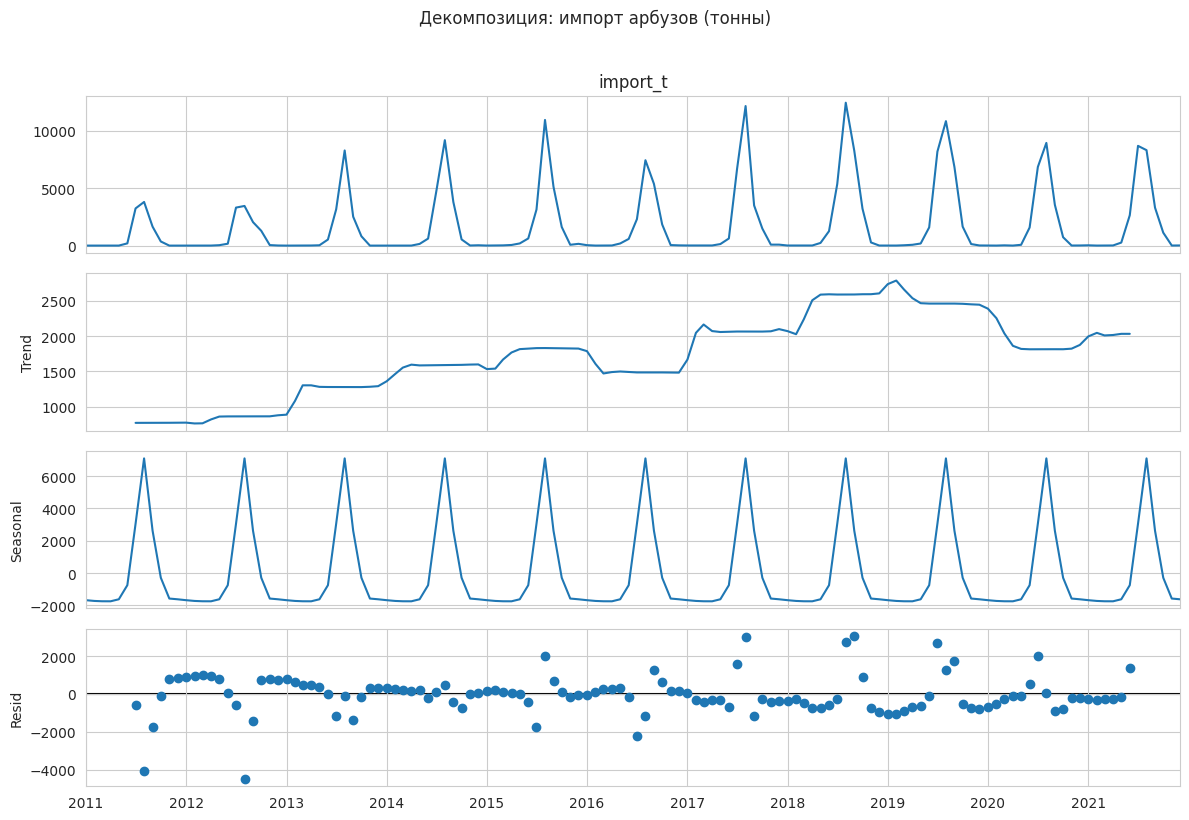


Интерпретация декомпозиции:
- Тренд — долгосрочное изменение объёмов
- Сезонность — пик летом/осенью, спад зимой
- Остаток — случайные отклонения



In [12]:
series_dec = imp["import_t"].dropna()

# period=12 — годовая сезонность для месячных данных
decomp = seasonal_decompose(series_dec, model="additive", period=12)

fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Декомпозиция: импорт арбузов (тонны)", y=1.02)
plt.tight_layout()
plt.show()

print("""
Интерпретация декомпозиции:
- Тренд — долгосрочное изменение объёмов
- Сезонность — пик летом/осенью, спад зимой
- Остаток — случайные отклонения
""")

# Вспомогательные функции

In [13]:
def train_test_split_ts(series, test_size=24):
    """Последние test_size месяцев — тест."""
    return series.iloc[:-test_size], series.iloc[-test_size:]


def fit_sarima(series):
    """SARIMA на логарифме ряда."""
    y = np.log(series.replace(0, np.nan)).dropna()
    model = SARIMAX(
        y,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return model.fit(disp=False)


def sarima_forecast(series, steps):
    """Прогноз SARIMA + 80% доверительный интервал."""
    res = fit_sarima(series)
    fc = res.get_forecast(steps=steps)
    mean = np.exp(fc.predicted_mean)
    ci = np.exp(fc.conf_int(alpha=0.20))

    idx = pd.date_range(
        series.index[-1] + pd.offsets.MonthBegin(1),
        periods=steps,
        freq="MS"
    )
    mean.index = idx
    ci.index = idx
    return mean, ci.iloc[:, 0], ci.iloc[:, 1]


def make_lag_features(series, n_lags=12):
    """Признаки для XGBoost: лаги + месяц."""
    d = pd.DataFrame({"y": series})
    for lag in range(1, n_lags + 1):
        d[f"lag{lag}"] = d["y"].shift(lag)
    d["month"] = d.index.month
    d = d.dropna()
    X = d.drop(columns=["y"])
    y = d["y"]
    return X, y


def xgb_forecast(series, steps, n_lags=12):
    """Рекурсивный прогноз XGBoost."""
    y_log = np.log(series.replace(0, np.nan)).dropna()
    X, y = make_lag_features(y_log, n_lags)

    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42
    )
    model.fit(X, y)

    # рекурсивно на steps месяцев вперёд
    history = list(y_log.values)
    preds = []
    last_date = y_log.index[-1]

    for i in range(steps):
        lags = history[-n_lags:][::-1]  # lag1, lag2, ...
        month = (last_date + pd.offsets.MonthBegin(i + 1)).month
        row = np.array(lags + [month]).reshape(1, -1)
        pred = model.predict(row)[0]
        preds.append(pred)
        history.append(pred)

    idx = pd.date_range(
        last_date + pd.offsets.MonthBegin(1),
        periods=steps,
        freq="MS"
    )
    return pd.Series(np.exp(preds), index=idx)


def calc_mape(y_true, y_pred):
    """MAPE, игнорируя нули."""
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return mean_absolute_percentage_error(y_true[mask], y_pred[mask])


def backtest_mape(series, forecast_func, test_size=24):
    """MAPE на последних test_size месяцах."""
    if len(series.dropna()) < test_size + 24:
        return np.nan
    train, test = train_test_split_ts(series.dropna(), test_size)
    try:
        pred = forecast_func(train, len(test))
        pred = pred.reindex(test.index)
        return calc_mape(test.values, pred.values)
    except Exception as e:
        print("  backtest ошибка:", e)
        return np.nan

# Прогноз по 4 показателям на 2022–2024 (36 месяцев)

In [14]:
HORIZON = 36  # янв 2022 — дек 2024

targets = [
    ("import_t",   imp["import_t"]),
    ("import_usd", imp["import_usd"]),
    ("export_t",   exp["export_t"]),
    ("export_usd", exp["export_usd"]),
]

results = {}

for name, series in targets:
    s = series.dropna().astype(float)
    print(f"\n{'='*50}")
    print(f"Показатель: {name} | точек: {len(s)}")

    if len(s) < 24:
        print("  мало данных — пропуск")
        continue

    # --- SARIMA ---
    try:
        sar_mean, sar_lo, sar_hi = sarima_forecast(s, HORIZON)
        mape_sar = backtest_mape(s, lambda tr, steps: sarima_forecast(tr, steps)[0])
    except Exception as e:
        print("  SARIMA ошибка:", e)
        sar_mean = sar_lo = sar_hi = None
        mape_sar = np.nan

    # --- XGBoost ---
    try:
        xgb_mean = xgb_forecast(s, HORIZON)
        mape_xgb = backtest_mape(s, xgb_forecast)
    except Exception as e:
        print("  XGBoost ошибка:", e)
        xgb_mean = None
        mape_xgb = np.nan

    print(f"  MAPE SARIMA  = {mape_sar:.3f}" if not np.isnan(mape_sar) else "  MAPE SARIMA  = n/a")
    print(f"  MAPE XGBoost = {mape_xgb:.3f}" if not np.isnan(mape_xgb) else "  MAPE XGBoost = n/a")

    # веса по качеству (меньше MAPE → больше вес)
    w_sar = 1 / (mape_sar + 1e-6) if not np.isnan(mape_sar) else 0
    w_xgb = 1 / (mape_xgb + 1e-6) if not np.isnan(mape_xgb) else 0
    total = w_sar + w_xgb
    if total == 0:
        w_sar, w_xgb = 0.5, 0.5
    else:
        w_sar, w_xgb = w_sar / total, w_xgb / total

    # ensemble
    if sar_mean is not None and xgb_mean is not None:
        ensemble = w_sar * sar_mean + w_xgb * xgb_mean
    elif sar_mean is not None:
        ensemble = sar_mean
    else:
        ensemble = xgb_mean

    print(f"  Веса: SARIMA={w_sar:.2f}, XGBoost={w_xgb:.2f}")

    results[name] = {
        "sarima": sar_mean,
        "xgb": xgb_mean,
        "ensemble": ensemble,
        "lower": sar_lo,
        "upper": sar_hi,
        "mape_sarima": mape_sar,
        "mape_xgb": mape_xgb,
    }


Показатель: import_t | точек: 132
  MAPE SARIMA  = 4.485
  MAPE XGBoost = 1.625
  Веса: SARIMA=0.27, XGBoost=0.73

Показатель: import_usd | точек: 132
  MAPE SARIMA  = 0.941
  MAPE XGBoost = 1.308
  Веса: SARIMA=0.58, XGBoost=0.42

Показатель: export_t | точек: 59
  SARIMA ошибка: No supported index is available.
  backtest ошибка: Input contains NaN.
  MAPE SARIMA  = n/a
  MAPE XGBoost = n/a
  Веса: SARIMA=0.50, XGBoost=0.50

Показатель: export_usd | точек: 59
  SARIMA ошибка: No supported index is available.
  backtest ошибка: Input contains NaN.
  MAPE SARIMA  = n/a
  MAPE XGBoost = n/a
  Веса: SARIMA=0.50, XGBoost=0.50


# Годовые итоги прогноза

In [15]:
print("\n" + "=" * 50)
print("ПРОГНОЗ ПО ГОДАМ (ensemble)")
print("=" * 50)

rows = []
for name, res in results.items():
    ens = res["ensemble"]
    if ens is None:
        continue
    yearly = ens.groupby(ens.index.year).sum()
    for year, val in yearly.items():
        rows.append({"показатель": name, "год": year, "прогноз": round(val, 1)})

summary = pd.DataFrame(rows)
print(summary.pivot(index="год", columns="показатель", values="прогноз"))


ПРОГНОЗ ПО ГОДАМ (ensemble)
показатель  export_t  export_usd  import_t  import_usd
год                                                   
2021           229.3     34743.6       NaN         NaN
2022           241.8     53955.5   25006.1   5165664.3
2023           325.9     56000.3   26183.2   5319574.3
2024            58.9     29067.1   24016.6   5255387.0


# Визуализация прогноза

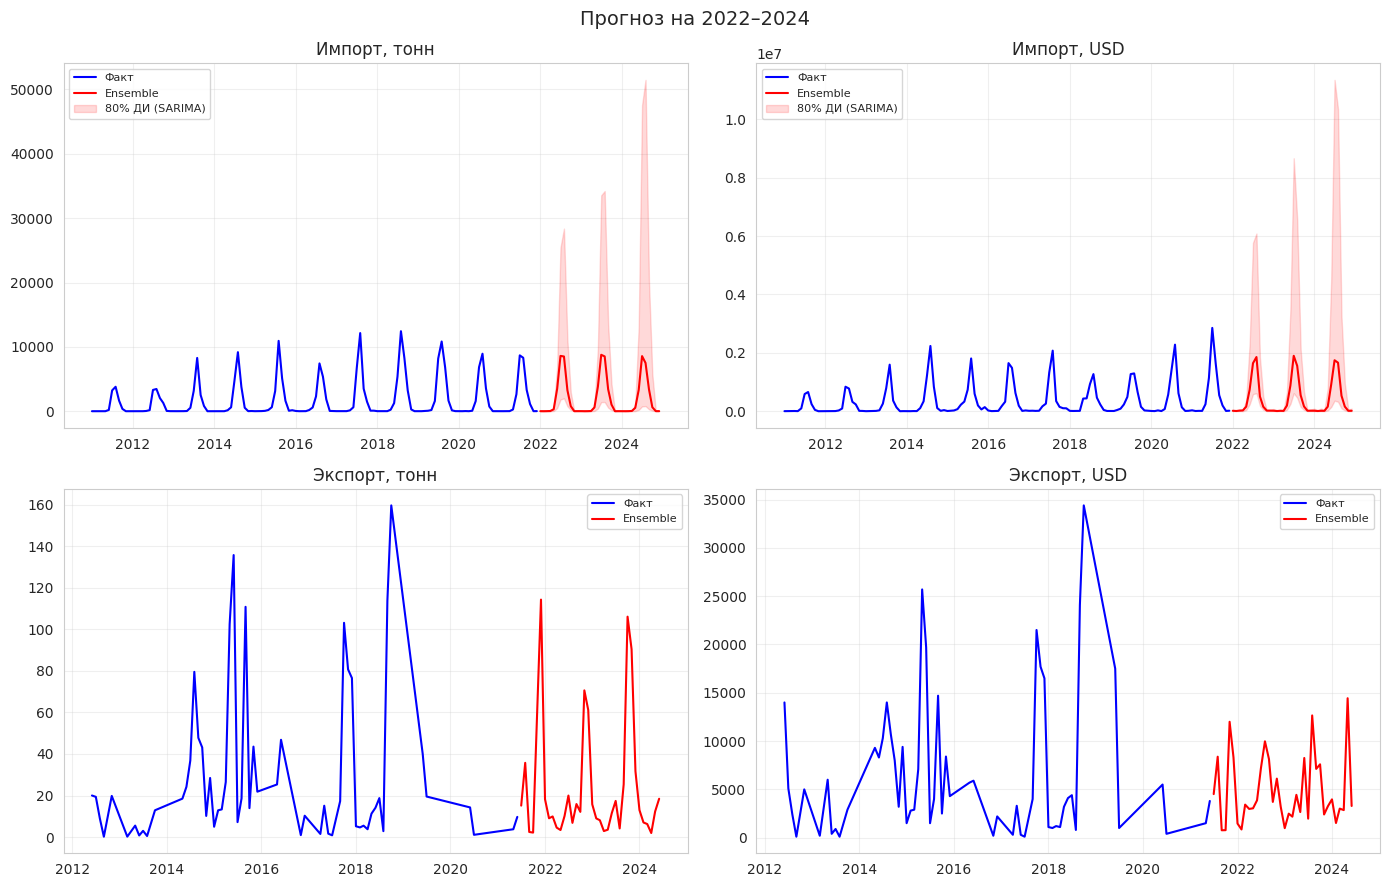

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
titles = {
    "import_t": "Импорт, тонн",
    "import_usd": "Импорт, USD",
    "export_t": "Экспорт, тонн",
    "export_usd": "Экспорт, USD",
}

for ax, name in zip(axes.ravel(), ["import_t", "import_usd", "export_t", "export_usd"]):
    if name not in results:
        ax.set_visible(False)
        continue

    res = results[name]
    # факт
    if name.startswith("import"):
        hist = imp[name].dropna()
    else:
        hist = exp[name].dropna()

    ax.plot(hist.index, hist.values, "b-", label="Факт", linewidth=1.5)

    if res["ensemble"] is not None:
        ax.plot(res["ensemble"].index, res["ensemble"].values,
                "r-", label="Ensemble", linewidth=1.5)

    if res["lower"] is not None:
        ax.fill_between(res["lower"].index, res["lower"], res["upper"],
                        color="red", alpha=0.15, label="80% ДИ (SARIMA)")

    ax.set_title(titles[name])
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Прогноз на 2022–2024", fontsize=14)
plt.tight_layout()
plt.show()

# Корреляция с курсом BYN/USD

In [19]:
uploaded2 = files.upload()

Saving currency_monthly_average.xlsx to currency_monthly_average (2).xlsx


Курс: период 2008-01-01 — 2024-12-01
            usd_byn
month              
2008-01-01   0.2150
2008-02-01   0.2148
2008-03-01   0.2146
2008-04-01   0.2144
2008-05-01   0.2137

После объединения: (168, 3)
            import_usd  export_usd  usd_byn
month                                      
2008-01-01         NaN         NaN   0.2150
2008-02-01         NaN         NaN   0.2148
2008-03-01         NaN         NaN   0.2146
2008-04-01         NaN         NaN   0.2144
2008-05-01         NaN         NaN   0.2137

=== Корреляция Пирсона ===
            import_usd  export_usd  usd_byn
import_usd       1.000      -0.064    0.161
export_usd      -0.064       1.000    0.060
usd_byn          0.161       0.060    1.000

=== Корреляция Спирмена ===
            import_usd  export_usd  usd_byn
import_usd       1.000       0.069    0.201
export_usd       0.069       1.000    0.023
usd_byn          0.201       0.023    1.000
Импорт USD ↔ Курс: r = 0.161, p-value = 0.0658
Экспорт USD ↔ Курс: r = 0.060,

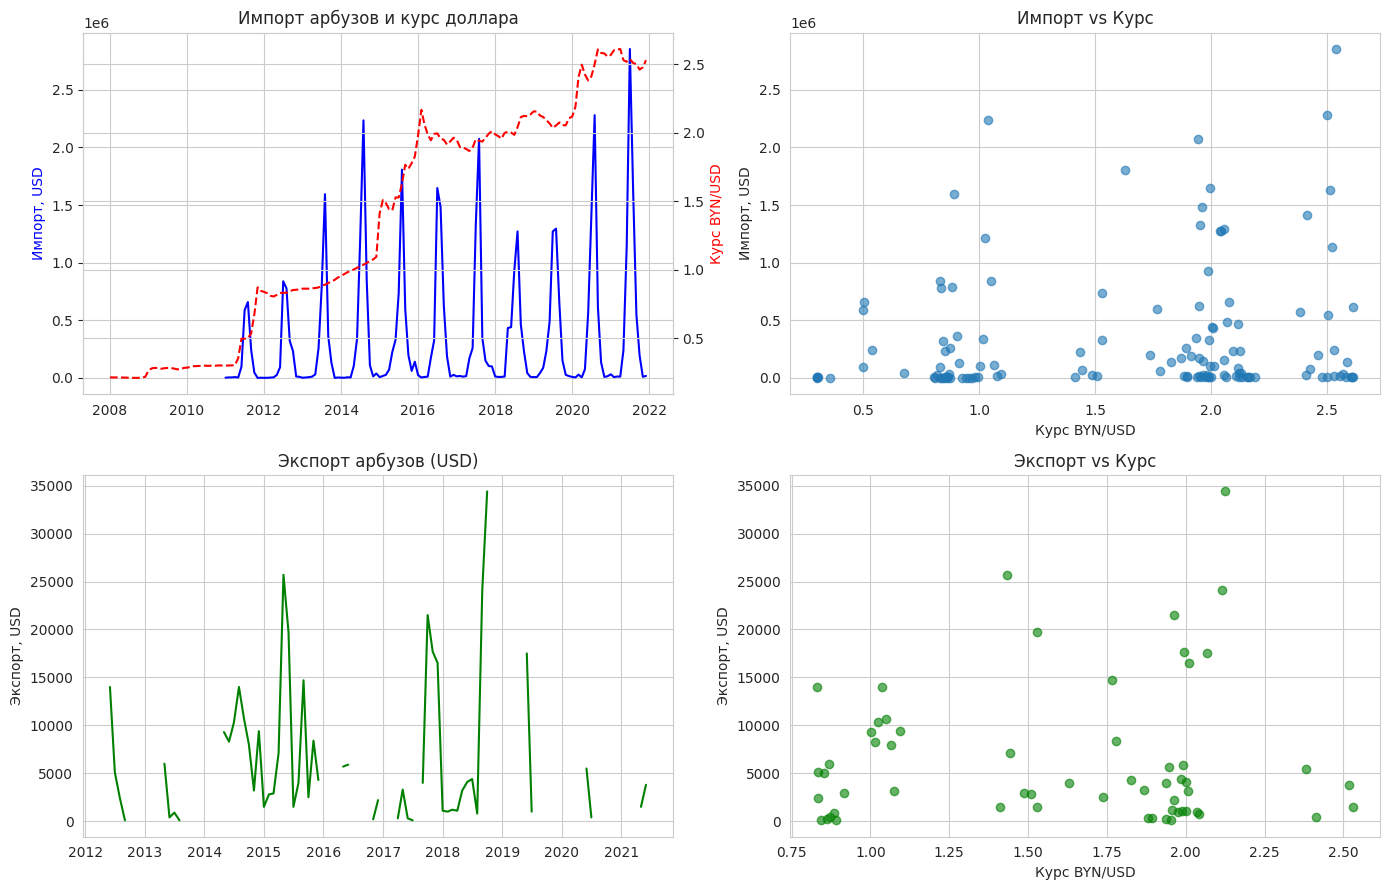

In [20]:
# файл: столбцы «Дата» (конец месяца) и «Курс_новый»
kurs = pd.read_excel("currency_monthly_average.xlsx")
kurs["Дата"] = pd.to_datetime(kurs["Дата"])

# приводим к первому числу месяца, чтобы стыковалось с рядами арбузов
kurs["month"] = kurs["Дата"].values.astype("datetime64[M]")
kurs = kurs.set_index("month")[["Курс_новый"]].rename(columns={"Курс_новый": "usd_byn"})
kurs = kurs[~kurs.index.duplicated(keep="last")]  # на всякий случай

print("Курс: период", kurs.index.min().date(), "—", kurs.index.max().date())
print(kurs.head())

# объединяем со стоимостью импорта/экспорта
merged = df[["import_usd", "export_usd"]].join(kurs, how="inner")
merged = merged.dropna(subset=["usd_byn"])

print("\nПосле объединения:", merged.shape)
print(merged.head())

# --- корреляции ---
print("\n=== Корреляция Пирсона ===")
print(merged[["import_usd", "export_usd", "usd_byn"]].corr().round(3))

print("\n=== Корреляция Спирмена ===")
print(merged[["import_usd", "export_usd", "usd_byn"]].corr(method="spearman").round(3))

# p-value
for col, label in [("import_usd", "Импорт USD"), ("export_usd", "Экспорт USD")]:
    sub = merged[[col, "usd_byn"]].dropna()
    if len(sub) < 5:
        print(f"{label}: мало данных")
        continue
    r, p = stats.pearsonr(sub[col], sub["usd_byn"])
    print(f"{label} ↔ Курс: r = {r:.3f}, p-value = {p:.4f}")

# лаг 1 месяц: курс прошлого месяца → текущая стоимость
merged = merged.copy()
merged["usd_byn_lag1"] = merged["usd_byn"].shift(1)

print("\n=== Корреляция с лагом 1 месяц ===")
for col, label in [("import_usd", "Импорт USD"), ("export_usd", "Экспорт USD")]:
    sub = merged[[col, "usd_byn_lag1"]].dropna()
    if len(sub) < 5:
        continue
    r, p = stats.pearsonr(sub[col], sub["usd_byn_lag1"])
    print(f"{label} ↔ Курс (лаг 1): r = {r:.3f}, p-value = {p:.4f}")

# --- графики ---
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) импорт и курс на одной оси времени
ax = axes[0, 0]
ax.plot(merged.index, merged["import_usd"], "b-", label="Импорт USD")
ax.set_ylabel("Импорт, USD", color="b")
ax2 = ax.twinx()
ax2.plot(merged.index, merged["usd_byn"], "r--", label="Курс")
ax2.set_ylabel("Курс BYN/USD", color="r")
ax.set_title("Импорт арбузов и курс доллара")

# 2) scatter импорт vs курс
axes[0, 1].scatter(merged["usd_byn"], merged["import_usd"], alpha=0.6)
axes[0, 1].set_xlabel("Курс BYN/USD")
axes[0, 1].set_ylabel("Импорт, USD")
axes[0, 1].set_title("Импорт vs Курс")

# 3) экспорт во времени
axes[1, 0].plot(merged.index, merged["export_usd"], "g-")
axes[1, 0].set_title("Экспорт арбузов (USD)")
axes[1, 0].set_ylabel("Экспорт, USD")

# 4) scatter экспорт vs курс
axes[1, 1].scatter(merged["usd_byn"], merged["export_usd"], alpha=0.6, color="green")
axes[1, 1].set_xlabel("Курс BYN/USD")
axes[1, 1].set_ylabel("Экспорт, USD")
axes[1, 1].set_title("Экспорт vs Курс")

plt.tight_layout()
plt.show()